# Экзаменационная задача №08. Расчёт юнит-экономики для сервиса доставки еды

**Дисциплина:** Экономика информатизации, лекция №9
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №08: РАСЧЁТ ЮНИТ-ЭКОНОМИКИ ДЛЯ СЕРВИСА ДОСТАВКИ ЕДЫ
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №9)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Стартап «Еда-Быстро» запускает доставку готовой еды. Прежде чем тратить деньги на рекламу, нужно понять, зарабатывает ли
бизнес на **одной единице**: одном заказе и одном клиенте. Юнит-экономика отвечает на три вопроса: приносит ли заказ прибыль,
окупается ли привлечение клиента (LTV/CAC, payback) и сколько нужно клиентов, чтобы покрыть постоянные расходы.

**Цель:** посчитать юнит-экономику, оценить, жизнеспособна ли модель, и предложить, как её улучшить.

**Важно про условие.** В условии есть и «комиссия сервиса 20 % от чека», и полная себестоимость заказа
(продукты, упаковка, доставка). Отсюда две возможные модели:
- **Модель А (агрегатор):** сервис получает только комиссию 20 % (120 руб.), но платит за всё выполнение заказа;
- **Модель Б (своя кухня):** сервис сам готовит и продаёт еду, его доход весь чек 600 руб.

Модель А это буквальное прочтение условия (под неё написаны формулы ARPU и LTV в задании). Модель Б логичнее:
кто платит за продукты, тот и получает за них деньги. Считаем обе и сравниваем.

Тема лекции №9: юнит-экономика, маржинальный доход, ARPU, LTV, CAC, LTV/CAC, payback, отток, точка безубыточности.

## 2. Исходные данные

In [2]:
# 1.1. Модель сервиса (из условия)
check = 600            # средний чек, руб.
orders_m = 2.5         # заказов в месяц на клиента
commission = 0.20      # комиссия сервиса от чека
lifetime = 12          # срок жизни клиента, мес.
CAC = 2_500            # стоимость привлечения клиента, руб.
churn = 0.08           # месячный отток
clients = 1_000        # активные клиенты
# 1.2. Переменные затраты на заказ, руб.
var = {"Себестоимость продуктов": 250, "Упаковка": 30, "Доставка": 120, "Комиссия платёжных систем (3%)": 0.03 * check, "Операционные затраты": 50}
# 1.3. Постоянные затраты, руб./мес.
fixed = {"Разработка и поддержка платформы": 500_000, "Маркетинг": 300_000, "Зарплаты менеджеров": 600_000, "Аренда офиса": 200_000}
display(pd.DataFrame({"руб./заказ": var}))
pd.DataFrame({"руб./мес.": fixed})

,руб./заказ
Себестоимость продуктов,250.00
Упаковка,30.00
Доставка,120.00
Комиссия платёжных систем (3%),18.00
Операционные затраты,50.00


,руб./мес.
Разработка и поддержка платформы,500000
Маркетинг,300000
Зарплаты менеджеров,600000
Аренда офиса,200000


## 3. Математическая модель

$$CM_{заказ} = Доход_{заказ} - \sum VC_{заказ},\qquad ARPU = Доход_{заказ}\cdot n_{заказов},\qquad CM_{клиент} = CM_{заказ}\cdot n_{заказов}$$
$$LTV_{выр} = \frac{ARPU}{churn}\ (\text{формула курса}),\qquad LTV_{маржа} = \frac{CM_{клиент}}{churn},\qquad Payback=\frac{CAC}{CM_{клиент}}$$
$$\Pi_{опер} = N\cdot CM_{клиент} - FC,\qquad N_{безуб} = \frac{FC}{CM_{клиент}}\ \ (CM_{клиент}>0)$$
Срок жизни 12 мес. почти совпадает с оттоком: $1/0{,}08 = 12{,}5$ мес. Сравнивать с CAC правильнее LTV по марже:
LTV по выручке завышает ценность клиента, потому что не учитывает затраты на выполнение заказов.

## 4. Реализация расчёта
### 4.1. Экономика заказа и клиента (две модели)

In [3]:
VC = sum(var.values()); FC = sum(fixed.values())
def unit(revenue_per_order, n=orders_m, ch=churn, cac=CAC, vc=VC, fc=FC, N=clients):
    cm_order = revenue_per_order - vc
    arpu = revenue_per_order * n
    cm_client = cm_order * n
    res = {"Доход с заказа, руб.": revenue_per_order, "Переменные затраты, руб.": vc, "Маржа заказа CM, руб.": cm_order,
           "ARPU, руб./мес.": arpu, "Маржа клиента, руб./мес.": cm_client,
           "LTV по выручке (ARPU/churn), руб.": arpu / ch, "LTV по марже, руб.": cm_client / ch,
           "LTV(выр)/CAC": arpu / ch / cac, "LTV(маржа)/CAC": cm_client / ch / cac,
           "Payback, мес.": cac / cm_client if cm_client > 0 else np.inf,
           "Доход сервиса в месяц, руб.": arpu * N, "Маржа всех клиентов, руб./мес.": cm_client * N,
           "Постоянные затраты, руб./мес.": fc, "Операционная прибыль, руб./мес.": cm_client * N - fc,
           "Клиентов для безубыточности": fc / cm_client if cm_client > 0 else np.inf}
    return pd.Series(res)

units = pd.DataFrame({"Модель А (агрегатор, доход = 20%)": unit(commission * check),
                      "Модель Б (своя кухня, доход = чек)": unit(check)})
units.round(2)

,"Модель А (агрегатор, доход = 20%)","Модель Б (своя кухня, доход = чек)"
"Доход с заказа, руб.",120.00,600.00
"Переменные затраты, руб.",468.00,468.00
"Маржа заказа CM, руб.",-348.00,132.00
"ARPU, руб./мес.",300.00,1 500.00
"Маржа клиента, руб./мес.",-870.00,330.00
"LTV по выручке (ARPU/churn), руб.",3 750.00,18 750.00
"LTV по марже, руб.",-10 875.00,4 125.00
LTV(выр)/CAC,1.50,7.50
LTV(маржа)/CAC,-4.35,1.65
"Payback, мес.",inf,7.58


In [4]:
# Детализация заказа (водопад) для обеих моделей
def waterfall(rev):
    rows = [("Доход с заказа", rev)] + [(k, -v) for k, v in var.items()]
    rows.append(("Маржа заказа", rev - VC))
    return pd.DataFrame(rows, columns=["Статья", "руб."]).set_index("Статья")
display(pd.concat({"Модель А": waterfall(commission * check), "Модель Б": waterfall(check)}, axis=1).round(1))
# Проверка затрат на привлечение: сколько стоит замещение оттока
replace_cost = clients * churn * CAC
print(f"Замещение оттока: {clients}·{churn:.0%}·{CAC} = {replace_cost:,.0f} руб./мес. — сравнимо с бюджетом маркетинга {fixed['Маркетинг']:,} руб.".replace(",", " "))

,Модель А,Модель Б
,руб.,руб.
Статья,,
Доход с заказа,120.00,600.00
Себестоимость продуктов,-250.00,-250.00
Упаковка,-30.00,-30.00
Доставка,-120.00,-120.00
Комиссия платёжных систем (3%),-18.00,-18.00
Операционные затраты,-50.00,-50.00
Маржа заказа,-348.00,132.00


Замещение оттока: 1000·8%·2500 = 200 000 руб./мес. — сравнимо с бюджетом маркетинга 300 000 руб.


### 4.2. Сценарий улучшения

Для модели А проверяем набор мер: комиссия 25 %, себестоимость на 50 руб. меньше, 3 заказа в месяц, отток 5 %, CAC 1 500 руб.
Для модели Б меры, которые поднимают маржу: чек на 100 руб. больше за счёт допродаж, доставка на 20 руб. дешевле
за счёт объединения заказов, отток 6 %, CAC 2 000 руб.

In [5]:
var_A2 = dict(var, **{"Себестоимость продуктов": 200})
improved = pd.DataFrame({
    "А: текущая": unit(commission * check),
    "А: улучшенная": unit(0.25 * check, n=3.0, ch=0.05, cac=1_500, vc=sum(var_A2.values())),
    "Б: текущая": unit(check),
    "Б: улучшенная": unit(700, n=2.5, ch=0.06, cac=2_000,
                         vc=sum(dict(var, **{"Доставка": 100, "Комиссия платёжных систем (3%)": 0.03 * 700}).values())),
})
improved.loc[["Маржа заказа CM, руб.", "ARPU, руб./мес.", "LTV по выручке (ARPU/churn), руб.", "LTV по марже, руб.",
              "LTV(маржа)/CAC", "Payback, мес.", "Операционная прибыль, руб./мес.", "Клиентов для безубыточности"]].round(2)

,А: текущая,А: улучшенная,Б: текущая,Б: улучшенная
"Маржа заказа CM, руб.",-348.00,-268.00,132.00,249.00
"ARPU, руб./мес.",300.00,450.00,1 500.00,1 750.00
"LTV по выручке (ARPU/churn), руб.",3 750.00,9 000.00,18 750.00,29 166.67
"LTV по марже, руб.",-10 875.00,-16 080.00,4 125.00,10 375.00
LTV(маржа)/CAC,-4.35,-10.72,1.65,5.19
"Payback, мес.",inf,inf,7.58,3.21
"Операционная прибыль, руб./мес.",-2 470 000.00,-2 404 000.00,-1 270 000.00,-977 500.00
Клиентов для безубыточности,inf,inf,4 848.48,2 570.28


In [6]:
# Чувствительность точки безубыточности (модель Б) к среднему чеку и частоте заказов
checks = np.arange(450, 901, 50); freqs = [2.0, 2.5, 3.0, 3.5]
be = pd.DataFrame({f"{f} зак./мес.": [FC / ((c - (VC - 0.03 * check + 0.03 * c)) * f) if (c - (VC - 0.03 * check + 0.03 * c)) > 0 else np.inf
                                      for c in checks] for f in freqs}, index=pd.Index(checks, name="Средний чек, руб."))
be.round(0)

,2.0 зак./мес.,2.5 зак./мес.,3.0 зак./мес.,3.5 зак./мес.
"Средний чек, руб.",,,,
450,inf,inf,inf,inf
500,22 857.00,18 286.00,15 238.00,13 061.00
550,9 581.00,7 665.00,6 387.00,5 475.00
600,6 061.00,4 848.00,4 040.00,3 463.00
650,4 432.00,3 546.00,2 955.00,2 533.00
700,3 493.00,2 795.00,2 329.00,1 996.00
750,2 883.00,2 306.00,1 922.00,1 647.00
800,2 454.00,1 963.00,1 636.00,1 402.00
850,2 136.00,1 709.00,1 424.00,1 221.00


## 5. Визуализация результатов

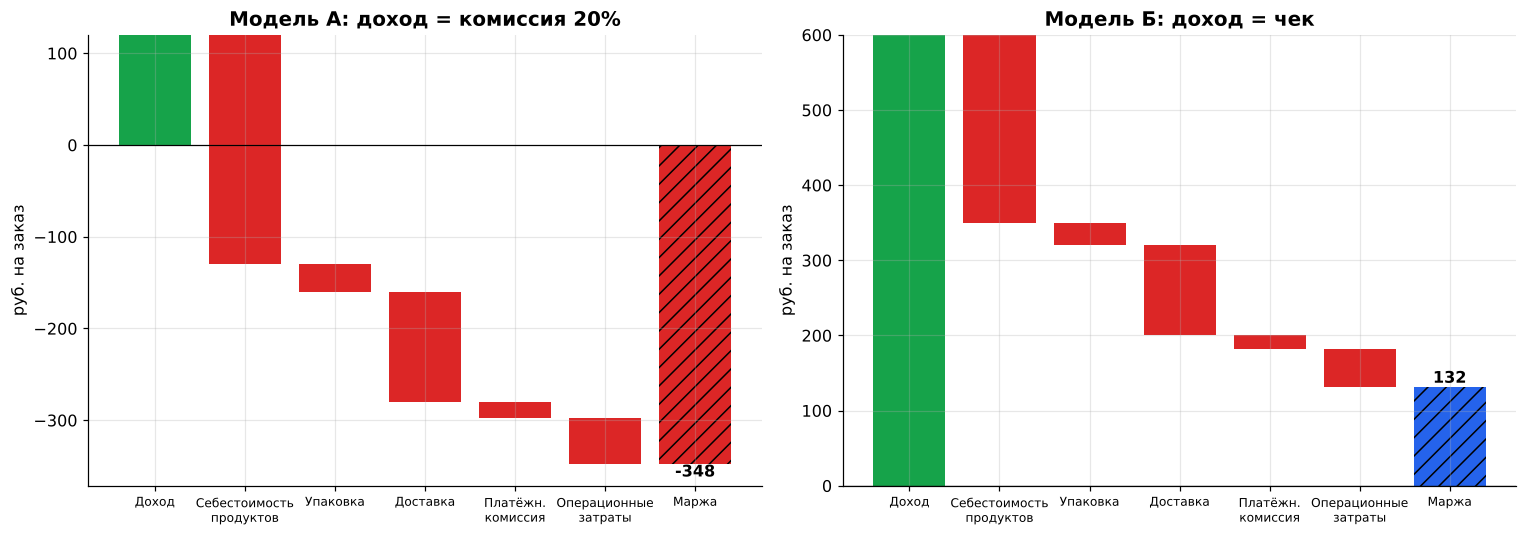

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, rev) in zip(axes, [("Модель А: доход = комиссия 20%", commission * check), ("Модель Б: доход = чек", check)]):
    labels = ["Доход"] + list(var.keys()) + ["Маржа"]
    vals = [rev] + [-v for v in var.values()]
    cum_ = np.concatenate([[0], np.cumsum(vals)])
    for i, v in enumerate(vals):
        ax.bar(i, v, bottom=cum_[i], color=PALETTE[2] if v >= 0 else PALETTE[1])
    m = rev - VC
    ax.bar(len(vals), m, color=PALETTE[0] if m >= 0 else PALETTE[1], hatch="//")
    ax.text(len(vals), m, f"{m:.0f}", ha="center", va="bottom" if m >= 0 else "top", fontweight="bold")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(range(len(labels)), [l.split(" (")[0].replace("Комиссия платёжных систем", "Платёжн.\nкомиссия").replace(" ", "\n", 1) for l in labels], fontsize=8)
    ax.set_title(name); ax.set_ylabel("руб. на заказ")
plt.tight_layout(); plt.show()

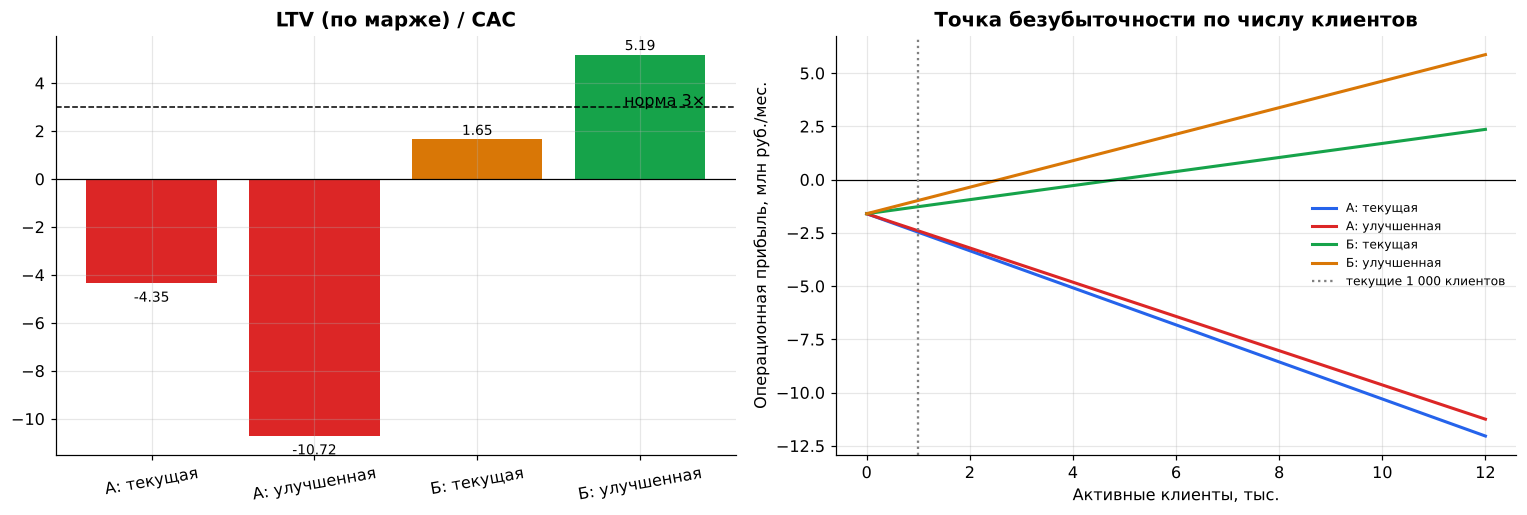

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
cols = ["А: текущая", "А: улучшенная", "Б: текущая", "Б: улучшенная"]
vals = improved.loc["LTV(маржа)/CAC", cols]
bars = ax.bar(cols, vals, color=[PALETTE[1] if v < 1 else (PALETTE[3] if v < 3 else PALETTE[2]) for v in vals])
bar_labels(ax, bars, "{:.2f}")
ax.axhline(3, ls="--", color="black", lw=1); ax.text(3.4, 3.05, "норма 3×", ha="right")
ax.axhline(0, color="black", lw=0.8); ax.set_title("LTV (по марже) / CAC"); ax.tick_params(axis="x", rotation=10)
ax = axes[1]
Ns = np.arange(0, 12001, 250)
for col, c in zip(cols, PALETTE):
    s = improved[col]
    ax.plot(Ns / 1e3, (s["Маржа клиента, руб./мес."] * Ns - FC) / 1e6, lw=2, label=col, color=c)
ax.axhline(0, color="black", lw=0.8); ax.axvline(clients / 1e3, color="gray", ls=":", label="текущие 1 000 клиентов")
ax.set_xlabel("Активные клиенты, тыс."); ax.set_ylabel("Операционная прибыль, млн руб./мес.")
ax.set_title("Точка безубыточности по числу клиентов"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

**Модель А (буквальная).** Сервис получает 120 руб. с заказа, а тратит 468 руб. Итог: **−348 руб. на каждом заказе**,
−870 руб. на клиента в месяц. ARPU 300 руб., LTV по формуле курса 3 750 руб., LTV/CAC 1,5, это ниже нормы 3.
А по марже LTV вообще отрицательный. Привлечение не окупается никогда, операционный убыток около **−2,47 млн руб. в месяц**
при 1 000 клиентах (870 тыс. убытка на заказах + 1,6 млн постоянных расходов). Безубыточности нет при любом числе клиентов:
каждый новый клиент только *увеличивает* убыток. Даже после всех улучшений заказ остаётся убыточным.
По сути сервис доплачивает за еду ресторанов, так работать нельзя.

**Модель Б (своя кухня).** Маржа заказа **+132 руб.** (22 % чека), на клиента 330 руб. в месяц, LTV по марже около 4 125 руб.,
LTV/CAC около 1,65, клиент окупается примерно за 7,6 месяца. При сроке жизни 12 месяцев он окупается, но запаса мало.
При 1 000 клиентов убыток около −1,27 млн руб. в месяц, безубыточность начинается примерно с **4 850 активных клиентов**.
После улучшений (чек 700 руб., дешевле доставка, отток 6 %) LTV/CAC больше 3, окупаемость меньше 5 месяцев,
а для безубыточности хватает примерно 2 500 клиентов.

**Главный вывод:** в обеих трактовках модель сейчас нежизнеспособна, LTV/CAC меньше 3. Основные рычаги: маржа заказа
(чек, себестоимость, доставка) и удержание клиентов. LTV обратно пропорционален оттоку.

## 7. Выводы и рекомендации

1. **Определиться с моделью бизнеса.** Если сервис агрегатор (модель А), он не должен платить за еду, это делает ресторан.
   Если у сервиса своя кухня (модель Б), его выручка весь чек. Смесь «комиссия 20 % + полная себестоимость» убыточна в принципе.
2. **Целевые метрики:** LTV(по марже)/CAC не меньше 3, окупаемость клиента не дольше 6 месяцев, маржа заказа от 25 % чека.

| Направление | Что делать | Эффект |
|---|---|---|
| Средний чек | комбо-наборы, допродажа напитков и десертов, минимальная сумма заказа | +100 руб. к чеку |
| Себестоимость | общие закупки, единое меню для кухни | −30…−50 руб. на заказ |
| Доставка | объединять заказы, зоны доставки, платная доставка для маленьких заказов | −20…−40 руб. на заказ |
| Частота | подписка на обеды для офисов (B2B), программа лояльности | +0,5 заказа в месяц |
| Удержание | контроль качества и времени доставки, личные предложения | отток 8 % → 5–6 % |
| CAC | реферальная программа, партнёрства с бизнес-центрами | 2 500 → 1 500–2 000 руб. |
| Постоянные расходы | не увеличивать маркетинг, пока LTV/CAC меньше 3 | экономия денег |

3. **Порядок действий:** сначала добиться нормальной маржи заказа на текущих клиентах, потом снижать отток,
   и только когда LTV/CAC дойдёт до 3, увеличивать бюджет на привлечение.